# v10 interpretability, part 2a: when does the self fire (H2) · what does it write (H3) · population picture (H5) — GPU 0
English → Hindi only, no training. Models: Hindi-only 45, continual 40 and 10, untrained model.

Needs `interp_v10.ipynb` to have run first (it finds the self and saves the token tables).
Results: `analysis/v10/interp2/` (report.txt + figures).

In [1]:
import os, sys, glob, json, time, subprocess
os.environ["HF_HUB_DISABLE_XET"] = "1"
GPU = "0"
REPO = "/workspace/shreshth"; os.chdir(REPO); sys.path.insert(0, REPO)
from IPython.display import Image, display
from huggingface_hub import HfApi, hf_hub_download
for attempt in range(5):
    try:
        api = HfApi(); HF_REPO = api.whoami()["name"] + "/cml-lang-self-checkpoints"; FILES = api.list_repo_files(HF_REPO); break
    except Exception as e:
        print("HF retry", attempt, type(e).__name__); time.sleep(10)

def get(run, phases):
    for ph in phases:
        if glob.glob(f"runs/{run}/ckpt/p{ph:03d}_*.pt"):
            continue
        name = [f for f in FILES if f.startswith(f"{run}/ckpt/p{ph:03d}_")]
        if name:
            hf_hub_download(HF_REPO, name[0], local_dir="runs")
        else:
            print("missing (not here, not on HF):", run, ph)

def last_phase(run):
    phs = [int(os.path.basename(f)[1:4]) for f in FILES if f.startswith(f"{run}/ckpt/p")]
    phs += [int(os.path.basename(f)[1:4]) for f in glob.glob(f"runs/{run}/ckpt/p*.pt")]
    return max(phs)


def run(*cmd):
    env = {**os.environ, "CML_LANGSET": "distant"}
    p = subprocess.Popen([sys.executable, "-u", "interp2_v10.py", "--gpu", GPU, *cmd], stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, env=env)
    for line in p.stdout:
        print(line, end="")
    p.wait(); print("exit code", p.returncode)

MODELS = [("hindi45", "v4b_only_hi_s0", 45), ("cont40", "v4b_continual_s0", 40), ("cont10", "v4b_continual_s0", 10)]
for _, r, ph in MODELS:
    get(r, [ph])
need = ["data/en-hi/train.jsonl", "tokenizer_v4/spm.model"] + [f"data/flores/dev.{l}.jsonl" for l in ["en", "hi", "zh", "ar"]]
miss = [f for f in need if not os.path.exists(f)]
print("all there" if not miss else f"MISSING: {miss}")

all there


In [2]:
import glob as _g
for f in ["h2_*.csv", "h3_*.csv", "h5_*.csv"]:
    for x in _g.glob("analysis/v10/interp2/" + f): os.remove(x)
for n, r, ph in MODELS:
    run("--model", f"{n}={r}:{ph}", "--parts", "h2,h3,h5")
run("--model", "random=random", "--parts", "h2,h3,h5")

30 most common Hindi words: के है में और की से को का हैं पर कि एक लिए तो नहीं भी जो हो ने यह किया ही कर इस वह करने न था या अपने
recorded in 2s
  H2 enc0
  H2 enc1
  H2 enc2
  H2 enc3
  H2 dec0
  H2 dec1
  H2 dec2
  H2 dec3
  H3 dec0
  H3 dec1
  H3 dec2
  H3 dec3
  H5 enc0
  H5 enc1
  H5 enc2
  H5 enc3
/venv/main/lib/python3.12/site-packages/numpy/_core/_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)
  H5 dec0
  H5 dec1
  H5 dec2
  H5 dec3
done
exit code 0
30 most common Hindi words: के है में और की से को का हैं पर कि एक लिए तो नहीं भी जो हो ने यह किया ही कर इस वह करने न था या अपने
recorded in 3s
  H2 enc0
  H2 enc1
  H2 enc2
  H2 enc3
  H2 dec0
  H2 dec1
  H2 dec2
  H2 dec3
  H3 dec0
  H3 dec1
  H3 dec2
  H3 dec3
  H5 enc0
  H5 enc1
  H5 enc2
  H5 enc3
/venv/main/lib/python3.12/site-packages/numpy/_core/_methods.py:188: RuntimeWarning: invalid value encountered in subtract
  x = um.subtract(arr, arrmean, out=...)
  H5 dec0

=== H2: when does the self fire? average z-activity, self minus task neurons (positive = self fires MORE on this kind) ===

-- by kind (rows: model, side; columns: category)
category      English word start  English word-piece  Hindi word start  Hindi word-piece  Latin  common word  number  other  punct
model   side                                                                                                                      
cont10  dec                  NaN                 NaN             0.004             0.012  0.025       -0.022  -0.036  0.116  0.012
        enc               -0.009              -0.030               NaN               NaN    NaN        0.034   0.078 -0.059  0.049
cont40  dec                  NaN                 NaN             0.004             0.014  0.022       -0.022  -0.053  0.112  0.013
        enc               -0.005              -0.007               NaN               NaN    NaN        0.012   0.065 -0.017  0.007
hindi45 dec                  NaN        

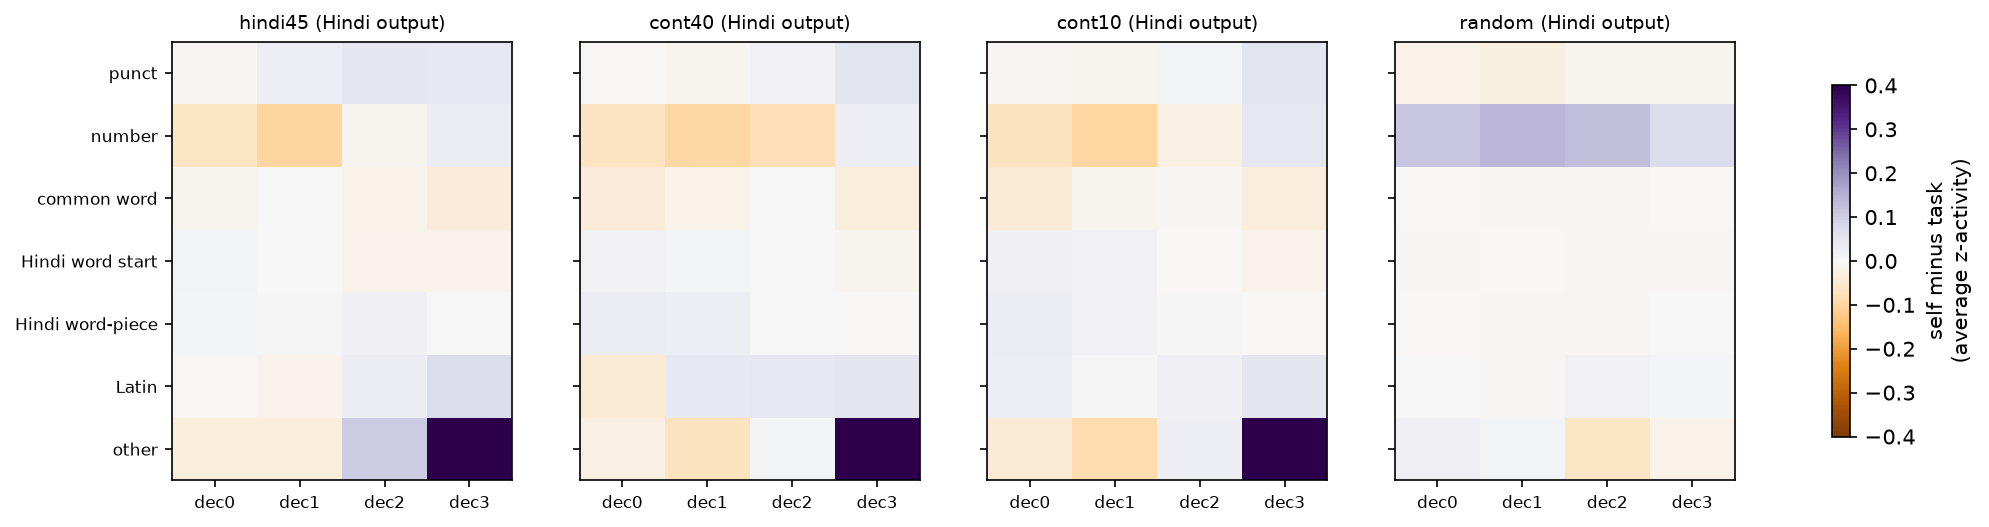

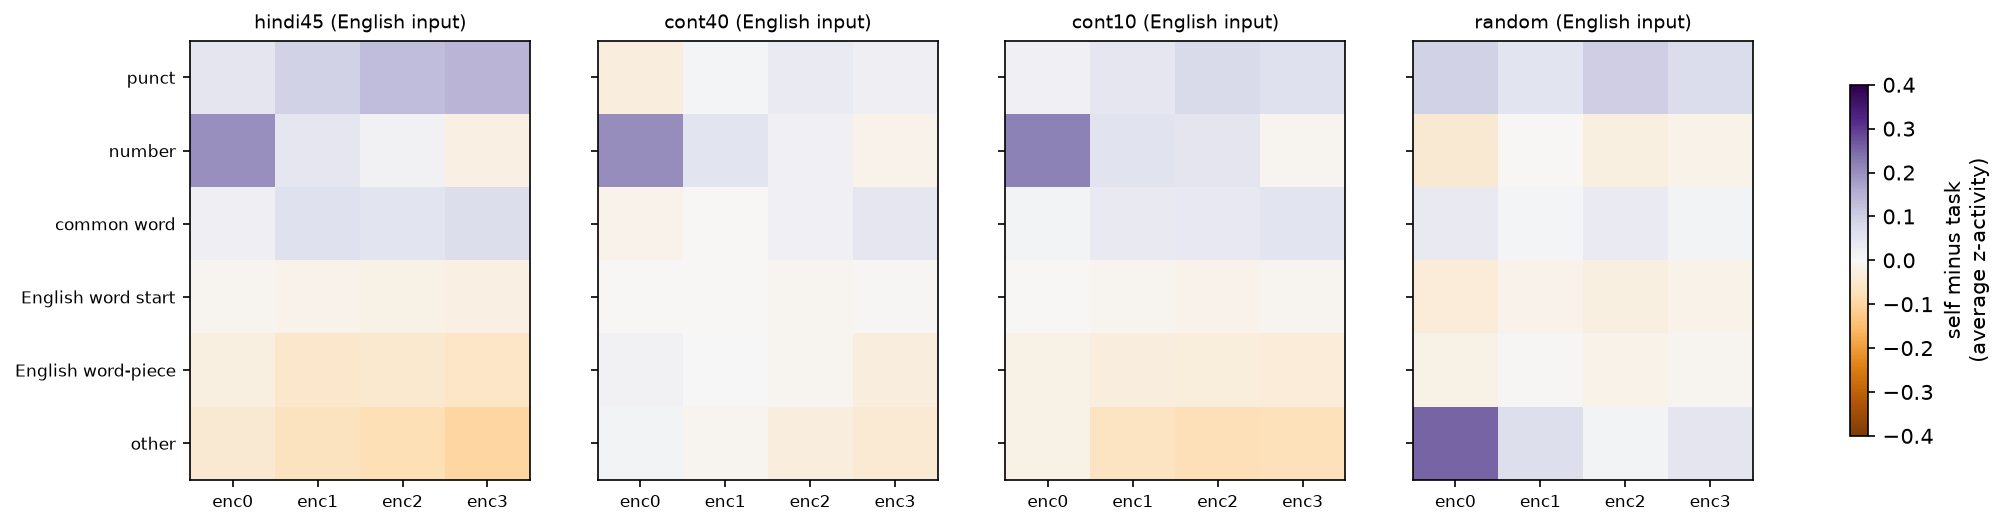

In [3]:
subprocess.run([sys.executable, "interp2_v10.py", "--summarize"])
for f in ["h2_kind_dec.png", "h2_kind_enc.png"]:
    if os.path.exists(f"analysis/v10/interp2/{f}"): display(Image(f"analysis/v10/interp2/{f}"))